In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt

plt.style.use("bmh")

In [2]:
# Read the cleaned cost of living dataset

df = pd.read_csv("../data/processed/pakistan_city_cost_of_living_cleaned.csv")

df.head()

,Item,Unit,Islamabad,Lahore,Karachi,Peshawar,Quetta
0,Wheat Flour Bag,20 Kg,3286.54,2477.84,3412.18,3038.96,3164.99
1,Rice Basmati Broken (Average Quality),1 Kg,274.83,228.47,283.54,222.18,279.93
2,Rice IRRI-6/9 (Sindh/Punjab),1 Kg,178.64,NaN,175.45,134.35,169.88
3,Bread plain (Small Size),Each,120.00,130.00,140.00,120.00,130.00
4,Beef with Bone (Average Quality),1 Kg,1491.13,1295.92,1470.13,1274.41,1274.10


In [3]:
# Check the basic information of the dataset

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Item       51 non-null     str    
 1   Unit       51 non-null     str    
 2   Islamabad  51 non-null     float64
 3   Lahore     50 non-null     float64
 4   Karachi    51 non-null     float64
 5   Peshawar   51 non-null     float64
 6   Quetta     51 non-null     float64
dtypes: float64(5), str(2)
memory usage: 2.9 KB


In [4]:
# Check missing values in the dataset

df.isna().sum()

Item         0
Unit         0
Islamabad    0
Lahore       1
Karachi      0
Peshawar     0
Quetta       0
dtype: int64

In [5]:
# Select the five cities for price comparison

cities = ["Islamabad", "Lahore", "Karachi", "Peshawar", "Quetta"]

city_price = df[cities]

city_price.head()

,Islamabad,Lahore,Karachi,Peshawar,Quetta
0,3286.54,2477.84,3412.18,3038.96,3164.99
1,274.83,228.47,283.54,222.18,279.93
2,178.64,NaN,175.45,134.35,169.88
3,120.00,130.00,140.00,120.00,130.00
4,1491.13,1295.92,1470.13,1274.41,1274.10


In [6]:
# Compare the prices of each item across all five cities

df[["Item"] + cities].head()

,Item,Islamabad,Lahore,Karachi,Peshawar,Quetta
0,Wheat Flour Bag,3286.54,2477.84,3412.18,3038.96,3164.99
1,Rice Basmati Broken (Average Quality),274.83,228.47,283.54,222.18,279.93
2,Rice IRRI-6/9 (Sindh/Punjab),178.64,NaN,175.45,134.35,169.88
3,Bread plain (Small Size),120.00,130.00,140.00,120.00,130.00
4,Beef with Bone (Average Quality),1491.13,1295.92,1470.13,1274.41,1274.10


In [7]:
# Find the city with the highest and lowest price for each item

df["Highest_Price_City"] = df[cities].idxmax(axis=1)
df["Lowest_Price_City"] = df[cities].idxmin(axis=1)

comparison = df[
    ["Item", "Highest_Price_City", "Lowest_Price_City"]
]

comparison.head()

,Item,Highest_Price_City,Lowest_Price_City
0,Wheat Flour Bag,Karachi,Lahore
1,Rice Basmati Broken (Average Quality),Karachi,Peshawar
2,Rice IRRI-6/9 (Sindh/Punjab),Islamabad,Peshawar
3,Bread plain (Small Size),Karachi,Islamabad
4,Beef with Bone (Average Quality),Islamabad,Quetta


In [8]:
# Calculate the maximum and minimum price of each item

df["Max_Price"] = df[cities].max(axis=1)
df["Min_Price"] = df[cities].min(axis=1)

df[["Item", "Max_Price", "Min_Price"]].head()

,Item,Max_Price,Min_Price
0,Wheat Flour Bag,3412.18,2477.84
1,Rice Basmati Broken (Average Quality),283.54,222.18
2,Rice IRRI-6/9 (Sindh/Punjab),178.64,134.35
3,Bread plain (Small Size),140.00,120.00
4,Beef with Bone (Average Quality),1491.13,1274.10


In [9]:
# Calculate the price difference between the highest and lowest city

df["price_difference"] = df["Max_Price"] - df["Min_Price"]

df[["Item", "Max_Price", "Min_Price", "price_difference"]].head()

,Item,Max_Price,Min_Price,price_difference
0,Wheat Flour Bag,3412.18,2477.84,934.34
1,Rice Basmati Broken (Average Quality),283.54,222.18,61.36
2,Rice IRRI-6/9 (Sindh/Punjab),178.64,134.35,44.29
3,Bread plain (Small Size),140.00,120.00,20.00
4,Beef with Bone (Average Quality),1491.13,1274.10,217.03


In [10]:
# Find the top five items with the highest price difference

top_5_difference = df.sort_values(
    by="price_difference",
    ascending=False
).head(5)

top_5_difference[
    ["Item", "Max_Price", "Min_Price", "price_difference"]
].round(2)

,Item,Max_Price,Min_Price,price_difference
42,Firewood Whole,2289.99,1329.77,960.22
0,Wheat Flour Bag,3412.18,2477.84,934.34
5,Mutton (Average Quality),2928.23,2347.75,580.48
34,Shirting (Average Quality),800.00,306.37,493.63
48,LPG 11.67 kg Cylinder,6631.21,6232.62,398.59


In [11]:
# Calculate percentage variation between maximum and minimum prices

df["difference_Percentage"] = (
    (df["Max_Price"] - df["Min_Price"]) / df["Min_Price"]
) * 100

df[["Item", "price_difference", "difference_Percentage"]].head(7).round(2)

,Item,price_difference,difference_Percentage
0,Wheat Flour Bag,934.34,37.71
1,Rice Basmati Broken (Average Quality),61.36,27.62
2,Rice IRRI-6/9 (Sindh/Punjab),44.29,32.97
3,Bread plain (Small Size),20.00,16.67
4,Beef with Bone (Average Quality),217.03,17.03
5,Mutton (Average Quality),580.48,24.72
6,Chicken Farm Broiler (Live),112.23,28.20


In [12]:
# Find the top five items with the highest percentage price variation

top_5 = df.sort_values(
    by="difference_Percentage",
    ascending=False
).head(5)

top_5[
    ["Item", "price_difference", "difference_Percentage"]
].round(2)

,Item,price_difference,difference_Percentage
34,Shirting (Average Quality),493.63,161.12
22,Tomatoes,92.41,123.18
15,Bananas (Kela) Local,116.93,117.92
43,Energy Saver Philips 14 Watt,273.37,98.82
36,Georgette (Average Quality),185.54,77.49


In [16]:
# Calculate the average prices of each city

cities = ["Islamabad", "Lahore", "Karachi", "Peshawar", "Quetta"]

avg_prices = df[cities].mean()

avg_prices

Islamabad    817.340784
Lahore       788.101800
Karachi      783.865686
Peshawar     772.053333
Quetta       758.544118
dtype: float64

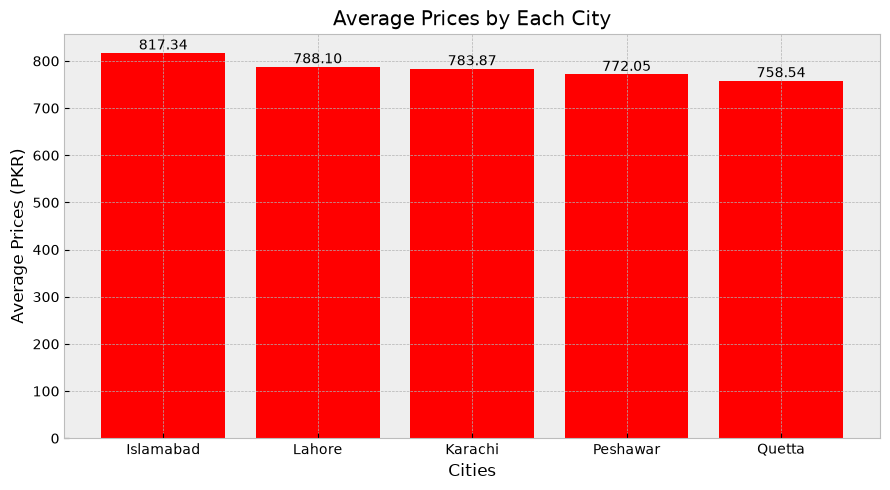

In [17]:
# Visualization of average prices by each city

plt.figure(figsize=(9, 5))

plt.bar(cities, avg_prices, color="red")

plt.title("Average Prices by Each City")
plt.xlabel("Cities")
plt.ylabel("Average Prices (PKR)")

for i in range(len(cities)):
    plt.text(
        i,
        avg_prices.iloc[i],
        f"{avg_prices.iloc[i]:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

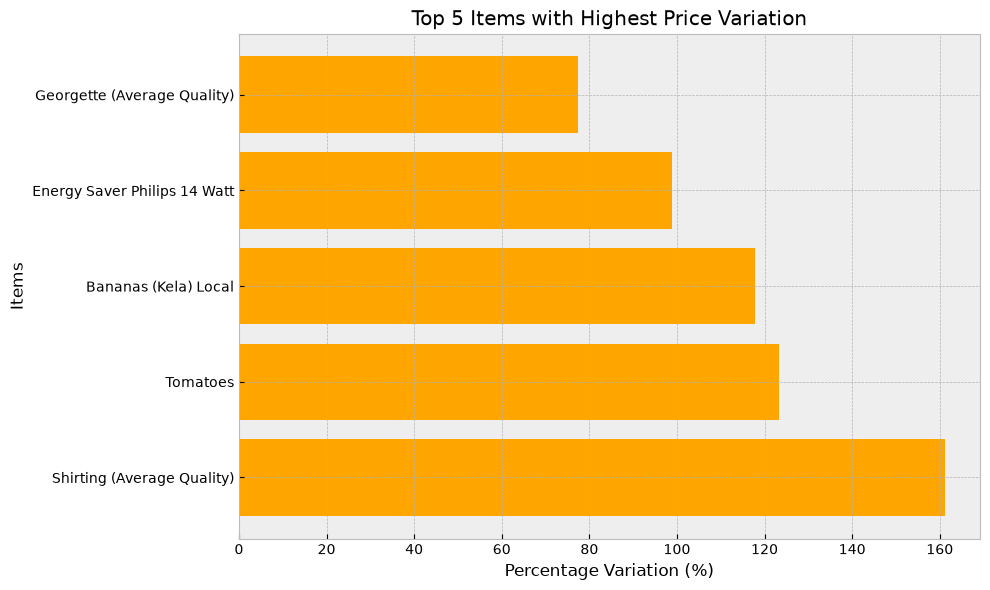

In [18]:
# Visualization of top five items with the highest percentage price variation

plt.figure(figsize=(10, 6))

plt.barh(
    top_5["Item"],
    top_5["difference_Percentage"],
    color="orange"
)

plt.title("Top 5 Items with Highest Price Variation")
plt.xlabel("Percentage Variation (%)")
plt.ylabel("Items")

plt.tight_layout()
plt.show()